In [4]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans

In [5]:
image_path = '../output_videos/playerimage_-1.jpg'
img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

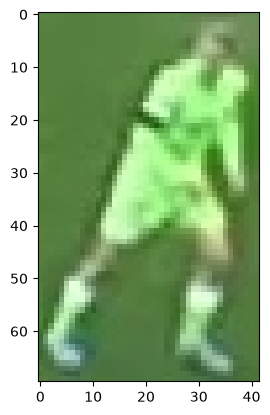

In [4]:
plt.imshow(img)
plt.show()

In [6]:
top_half_img = img[0:int(img.shape[0]/2), :]

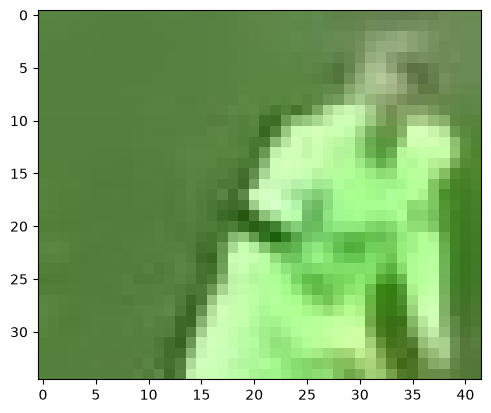

In [6]:
plt.imshow(top_half_img)
plt.show()

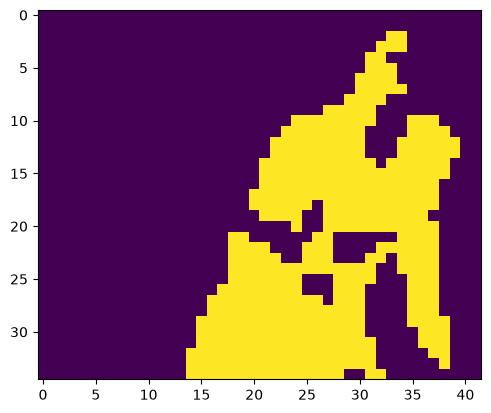

In [50]:
image_2d = top_half_img.reshape(-1, 3)

kmeans = KMeans(n_clusters=2, random_state=0)
kmeans.fit(image_2d)

# get cluster labels
labels = kmeans.labels_

# reshape labels to image
clust_img = labels.reshape(top_half_img.shape[0], top_half_img.shape[1])

plt.imshow(clust_img)
plt.show()

In [51]:
corner_clusters = [clust_img[0, 0], 
                   clust_img[-1, 0], 
                   clust_img[0, -1], 
                   clust_img[-1, -1]]
non_player_cluster = max(set(corner_clusters), key=corner_clusters.count)
non_player_cluster

np.int32(0)

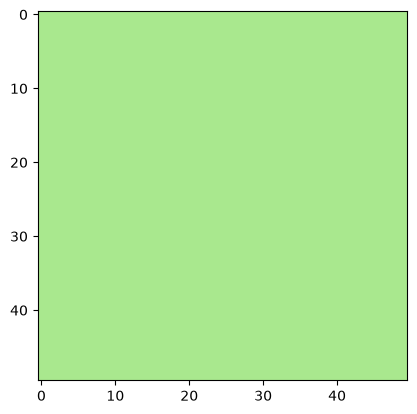

In [52]:
player_cluster = 1 - non_player_cluster
player_color = kmeans.cluster_centers_[player_cluster]
color_sample = np.full((50, 50, 3), player_color/255)
plt.imshow(color_sample)
plt.show()